# Clustering

I group the municipalities with similar road accident characteristics using KMeans.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score

In [9]:
df_mun = pd.read_csv("../data/processed/municipalities_2022_2024.csv", 
                     dtype={"municipality_code": str}, 
                     keep_default_na=False, na_values=[""])
df_mun.isnull().sum()

municipality_code             0
accidents_avg                 0
deaths_avg                    0
injured_avg                   0
municipality                  0
province                      0
region                        0
geographic_area               0
province_capital              0
population                    0
area_km2                      0
accidents_per_10k             0
accidents_per_km2             0
deaths_per_100_accidents    719
pop_density                   0
dtype: int64

I'm using municipalities with at least 10.000 inhabitants, as in the EDA, because in small municipalities the rates are unstable and would create groups based on chance.

In [3]:
df_big = df_mun[df_mun["population"] >= 10000].copy()
print(len(df_big))
df_big["deaths_per_100_accidents"].isnull().sum()

1202


np.int64(0)

So 1202 municipalities, with no missing values. I checked for missing values becaues KMeans does not accept them. So all municipalities have at least one accident, so there are none.

## Choosing columns

I'm choosing 4 variables that describe the road accident profile of a municipality:
1. accidents_per_10k, that shows how frequent accidents are for the residents, the risk per person;
2. accidents_per_km2, how concentrated accidents are in the territory;
3. deaths_per_100_accidents, how serious accidents are;
4. pop_density

In [4]:
variables = ["accidents_per_10k", "accidents_per_km2", "deaths_per_100_accidents", "pop_density"]
df_big[variables].describe()

,accidents_per_10k,accidents_per_km2,deaths_per_100_accidents,pop_density
count,1202.000000,1202.000000,1202.000000,1202.000000
mean,25.677718,2.317001,2.262866,933.552799
std,11.921674,3.343571,2.375520,1262.618662
min,1.299545,0.006766,0.000000,32.923989
25%,17.320658,0.571752,0.881447,251.676831
50%,23.800738,1.191623,1.769912,498.184336
75%,31.746823,2.567242,2.966260,1025.939580
max,78.434544,42.780023,31.428571,11315.020819


I see that pop_density goes from 30 to 11.000, deaths_per_100_accidents from 0 to 10, so they have very different scales.
I use rates and no totals beacause totals show the size of municipality. I want to group municipalities by type of risk instead.

For this reason (different scales of the variables)and also because KMeans uses distances, I normalize all variables between 0 and 1.

In [10]:
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(df_big[variables]), columns=variables)
X.describe().round(3)

,accidents_per_10k,accidents_per_km2,deaths_per_100_accidents,pop_density
count,1202.000,1202.000,1202.000,1202.000
mean,0.316,0.054,0.072,0.080
std,0.155,0.078,0.076,0.112
min,0.000,0.000,0.000,0.000
25%,0.208,0.013,0.028,0.019
50%,0.292,0.028,0.056,0.041
75%,0.395,0.060,0.094,0.088
max,1.000,1.000,1.000,1.000


After normalization all variables go from 0 to 1. I see that pop_density has most values almost 0, because very few dense cities have the maximum. These are real values, not errors, so I kept them.

## Deciding how many clusters

The elbow method (WCSS)

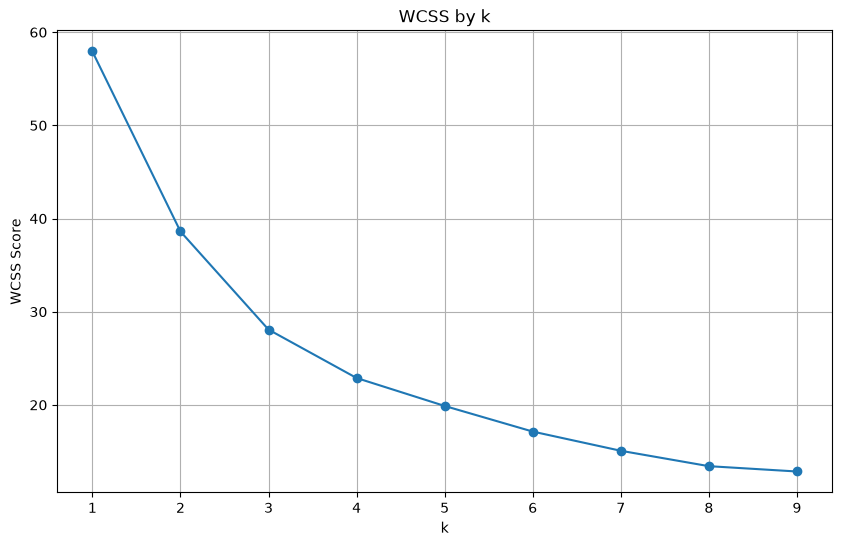

In [11]:
k_values = list(range(1, 10))
wcss_list = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    wcss_list.append(kmeans.inertia_)
    
plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list, marker="o")
plt.title("WCSS by k")
plt.xlabel("k")
plt.ylabel("WCSS Score")
plt.grid(True)
plt.show()

I see that the elbow of the WCSS curve is at k = 3.

Silhouette & Calinski-Harabasz

In [12]:
for k in range(2, 10):
    kmeans =KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)
    print("k=", k, "| Silhouette:", round(silhouette_score(X, labels), 3),
                    "| Calinski-Harabasz:", round(calinski_harabasz_score(X, labels)))

k= 2 | Silhouette: 0.397 | Calinski-Harabasz: 600
k= 3 | Silhouette: 0.421 | Calinski-Harabasz: 637
k= 4 | Silhouette: 0.315 | Calinski-Harabasz: 612
k= 5 | Silhouette: 0.327 | Calinski-Harabasz: 572
k= 6 | Silhouette: 0.339 | Calinski-Harabasz: 569
k= 7 | Silhouette: 0.324 | Calinski-Harabasz: 566
k= 8 | Silhouette: 0.311 | Calinski-Harabasz: 566
k= 9 | Silhouette: 0.325 | Calinski-Harabasz: 523


Both silhouette score and calinski-harabasz index are highest with k=3 (0.421, 637).
So all 3 methods agree.

## KMeans with 3 clusters

In [13]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)
df_big["cluster"] = kmeans.labels_
df_big["cluster"].value_counts()

cluster
0    789
1    326
2     87
Name: count, dtype: int64

Now I want to know what each cluster means.

In [14]:
df_big.groupby("cluster") [variables].mean().round(2)

,accidents_per_10k,accidents_per_km2,deaths_per_100_accidents,pop_density
cluster,,,,
0,20.04,1.13,2.66,586.82
1,40.78,3.43,1.51,819.98
2,20.25,8.86,1.51,4503.60


I found that:
- Cluster 0 is the largest group (789 municipalities) and it has about 20 accidents per 10.000 inhabitants and few accidents per km2, but the highest number of deaths per 100 accidents (2.66), so accidents are less frequent but more serious.
- Cluster 1 (326 municipalities) has the highest accident rate per inhabitant (40.78 per 10.000inhabitants), so it almost doubles the other clusters, so it groups the municipalities with the highest risk per inhabitant.
- Cluster 2 is the smallest group (87 municipalities), it has a very high population density (4500 inhabitants per km2) and the most accidents per km2 (8.86), but fewer deaths per 100 accidents (1.51), so it represents dense urban areas where accidents are frequent but less serious.

Examples of municipality - 
I want to know the 5 most populated municipalities of each cluster, to see which kind of towns are in each group.

In [ ]:
for c in range(3):
    print(c, df_big[df_big["cluster"] == c].sort_values("population", ascending=False) 
          ["municipality"].head(5).tolist())

0 ['Venezia', 'Reggio di Calabria', 'Perugia', 'Giugliano in Campania', 'Trento']
1 ['Roma', 'Genova', 'Bologna', 'Firenze', 'Bari']
2 ['Milano', 'Napoli', 'Torino', 'Palermo', 'Monza']


Describing the clusters with other columns

In [16]:
df_big.groupby("cluster")[["population", "province_capital"]].mean().round(2)

,population,province_capital
cluster,,
0,20840.29,0.04
1,55499.76,0.24
2,74030.67,0.07


In [17]:
pd.crosstab(df_big["cluster"], df_big["geographic_area"])

geographic_area,Centre,Islands,North-East,North-West,South
cluster,,,,,
0,114,105,181,168,221
1,101,21,89,74,41
2,1,7,0,40,39


In [18]:
pd.crosstab(df_big["cluster"], df_big["geographic_area"], normalize="columns").round(2)

geographic_area,Centre,Islands,North-East,North-West,South
cluster,,,,,
0,0.53,0.79,0.67,0.60,0.73
1,0.47,0.16,0.33,0.26,0.14
2,0.00,0.05,0.00,0.14,0.13


To check if the clusters make sense I looked at columns I did not use for clustering.
- Cluster 0 has the smallest municipalities and only 4% are province capitals. It is the largest group in every geographic area, especially in south and north-east in numbers and in islands and south in %. 
- In Cluster 1, 24% are province capitals, so I think these are cities where there are most commuters and turists. Thi would explain the high accident rate per inhabitant.
- Cluster 2 has the biggest municipalities and they are almost only in north-west a the south. I think these are areas around Milan and Naples because they are the densest cities in Italy.

In [19]:
cluster_names = {
    0: "Lower frequency, more serious accidents",
    1: "High risk per inhabitant",
    2: "Dense urban areas"
}
df_big["cluster_name"] = df_big["cluster"].map(cluster_names)
df_big["cluster_name"].value_counts()

cluster_name
Lower frequency, more serious accidents    789
High risk per inhabitant                   326
Dense urban areas                           87
Name: count, dtype: int64

### What this means?
Each cluster needs a different type of investment. I think municipalities with a high risk per inhabitant should be the priority for prevention because they have the most accidents compared to their residents.
Dense urban areas need better urban traffic management since accidents are frequent but less serious. Municipalities with fewer but more serious accidents need speed control and safer roads.

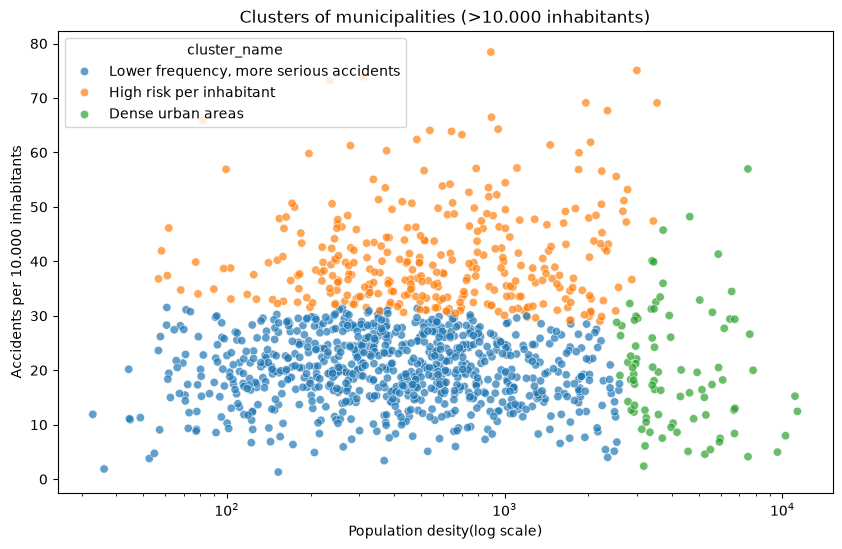

In [20]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_big, x="pop_density", y="accidents_per_10k",
               hue="cluster_name", alpha = 0.7)
plt.xscale("log")
plt.title("Clusters of municipalities (>10.000 inhabitants)")
plt.xlabel("Population desity(log scale)")
plt.ylabel("Accidents per 10.000 inhabitants")
plt.show()

In [21]:
df_mun =df_mun.merge(df_big[["municipality_code", "cluster_name"]], on = "municipality_code", how="left")
df_mun["cluster_name"] = df_mun["cluster_name"].fillna("Under 10.000 inhabitants")
print(df_mun["cluster_name"].value_counts())

df_mun.to_csv("../data/processed/municipalities_with_clusters.csv", index=False)
print("Saved")

cluster_name
Under 10.000 inhabitants                   6688
Lower frequency, more serious accidents     789
High risk per inhabitant                    326
Dense urban areas                            87
Name: count, dtype: int64
Saved


I added the cluster to all municipalities. Municipalitites under 10.000 inhabitants were not clustered so I labeled them "Under 10.000 inhabitants".